# Design verifiable rewards

        You maintain the extractor that sends supplier invoices to accounts payable. A synthetic invoice says EUR, but a tidy result says USD. A second result uses EUR and drops a printed line. Would your training reward treat either answer as a success?

        Replay those errors, then compare two rewards from one supervised checkpoint on the same held-out invoices.

        Select **T4 GPU** in Google Colab and run all cells in order. The staged steps and fixed evaluation slices
        are set below. Allow 35–50 minutes as a planning estimate, depending on sampled answer lengths.
        Time, memory and accuracy come from the recorded outputs.

        [Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/04-design-verifiable-rewards)

## 0. Environment

Install the pinned training libraries and keep the Colab CUDA PyTorch build. The notebook logs the PyTorch and CUDA versions.

In [1]:
import subprocess
import sys

TRAINER_PINS = {'transformers': '4.51.3', 'peft': '0.15.2', 'trl': '0.19.1', 'accelerate': '1.6.0', 'datasets': '3.6.0'}
pins = [f"{name}=={version}" for name, version in TRAINER_PINS.items()]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pins], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.51.3', 'peft==0.15.2', 'trl==0.19.1', 'accelerate==1.6.0', 'datasets==3.6.0'], returncode=0)

## 1. Invoice catalog

The synthetic inputs, split labels and independent evaluator are defined together. The model sees only the visible invoice text.

In [2]:
"""Versioned synthetic invoices and independent record scoring for the course."""

from __future__ import annotations

import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from datetime import date, timedelta
from typing import Any

CATALOG_VERSION = "course-invoice-v1"
SPLIT_SIZES = {"train": 576, "dev": 72, "familiar": 96, "novel": 96, "independent": 48, "release": 120}
VISIBLE_CONTRACT = (
    "Extract exactly one JSON object with invoice_id, issued_on (YYYY-MM-DD), supplier, "
    "currency (ISO code), line_items (description, quantity, unit_minor), subtotal_minor, "
    "tax_minor, and total_minor. Preserve line order and convert currency amounts to integer cents. "
    "Use null only for a missing or ambiguous field. Do not rewrite printed amounts, invent fields, or add explanations."
)

@dataclass(frozen=True)
class Line:
    description: str
    quantity: int
    unit_minor: int


@dataclass(frozen=True)
class Invoice:
    key: str
    family: str
    supplier: str
    issued_on: str
    currency: str
    items: tuple[Line, ...]
    tax_minor: int | None
    locale: str
    split: str
    layout: str = "register"
    printed_total_minor: int | None = None


def invoice_record(invoice: Invoice) -> dict[str, Any]:
    subtotal = sum(line.quantity * line.unit_minor for line in invoice.items)
    total = subtotal + invoice.tax_minor if invoice.tax_minor is not None else None
    if invoice.printed_total_minor is not None:
        total = invoice.printed_total_minor
    return {
        "invoice_id": invoice.key,
        "issued_on": invoice.issued_on,
        "supplier": invoice.supplier,
        "currency": invoice.currency,
        "line_items": [
            {"description": item.description, "quantity": item.quantity, "unit_minor": item.unit_minor}
            for item in invoice.items
        ],
        "subtotal_minor": subtotal,
        "tax_minor": invoice.tax_minor,
        "total_minor": total,
    }


def make_catalog() -> list[Invoice]:
    rng = random.Random(20261126)
    sources = {
        "train": (24, ("register", "memo", "checkout", "ledger")),
        "dev": (6, ("register", "memo", "checkout", "ledger")),
        "familiar": (8, ("register", "memo", "checkout", "ledger")),
        "novel": (8, ("packing", "remittance", "service", "notice")),
        "independent": (4, ("separate",)),
        "release": (10, ("packing", "remittance", "service", "notice", "separate")),
    }
    locales = (("en-US", "USD"), ("en-GB", "GBP"), ("de-DE", "EUR"), ("fr-FR", "EUR"), ("en-US", "CAD"))
    services = ("Cooling filter", "Cable sleeve", "Bench calibration", "Door seal", "Grounding clip",
                "Rack inspection", "Meter label", "Packing insert", "Carrier adjustment", "Mounting plate")
    catalog = []
    seen_keys = set()
    supplier_codes = rng.sample(range(1000, 9999), sum(n for n, _ in sources.values()))
    supplier_index = 0
    for split, (family_count, layouts) in sources.items():
        for family_number in range(family_count):
            supplier_code = supplier_codes[supplier_index]
            supplier_index += 1
            layout = layouts[family_number % len(layouts)]
            family = f"{split}-{family_number:02d}"
            locale, currency = locales[family_number % len(locales)]
            for row in range(SPLIT_SIZES[split] // family_count):
                code = f"SF-{rng.randrange(100000, 1000000)}"
                while code in seen_keys:
                    code = f"SF-{rng.randrange(100000, 1000000)}"
                seen_keys.add(code)
                items = tuple(
                    Line(kind, rng.randint(1, 9), rng.randrange(200, 24800))
                    for kind in rng.sample(services, rng.randrange(1, 4))
                )
                subtotal = sum(x.quantity * x.unit_minor for x in items)
                tax = (subtotal * (7 if currency == "USD" else 13) + 50) // 100
                if split in {"novel", "independent", "release"} and row % 12 == 4:
                    tax = None
                displayed = subtotal + tax + 101 if tax is not None and row % 12 == 7 else None
                issued_on = (date(2025, 1, 1) + timedelta(days=rng.randint(0, 590))).isoformat()
                catalog.append(Invoice(code, family, f"Sample Supplier {supplier_code}", issued_on,
                                       currency, items, tax, locale, split, layout, displayed))
    return catalog


def formatted_money(minor: int | None, locale: str) -> str:
    if minor is None:
        return "-"
    dollars, cents = divmod(minor, 100)
    number = f"{dollars:,}.{cents:02d}"
    if locale == "de-DE":
        return number.replace(",", "_").replace(".", ",").replace("_", ".")
    if locale == "fr-FR":
        return number.replace(",", " ").replace(".", ",")
    return number


def invoice_text(invoice: Invoice) -> str:
    gold = invoice_record(invoice)
    money = lambda value: formatted_money(value, invoice.locale)
    identifier = f"{invoice.key}"
    supplier = invoice.supplier
    issued = invoice.issued_on
    currency = invoice.currency
    subtotal = money(gold["subtotal_minor"])
    tax = money(gold["tax_minor"])
    total = money(gold["total_minor"])
    register = [f"{row.description} | {row.quantity} | {money(row.unit_minor)}" for row in invoice.items]
    inline = [f"{row.quantity} x {row.description} @ {money(row.unit_minor)} per unit" for row in invoice.items]
    service = [f"{row.description}: {money(row.unit_minor)} each for {row.quantity} units" for row in invoice.items]
    if invoice.layout == "register":
        return "\n".join([f"Supplier: {supplier}", f"Invoice: {identifier}", f"Issued: {issued}", f"Currency: {currency}",
                          "Description | Quantity | Unit price", *register,
                          f"Subtotal: {subtotal}", f"Tax: {tax}", f"Amount due: {total}"])
    if invoice.layout == "memo":
        return "\n".join([f"{supplier} billing memo / {issued}", f"Account invoice {identifier} [{currency}]",
                          *inline, f"Total due {total} including tax {tax}; net amount {subtotal}."])
    if invoice.layout == "checkout":
        return "\n".join([f"{identifier} / supplier {supplier}", f"Date of issue {issued} / All amounts {currency}",
                          *service, f"Net {subtotal}", f"Sales tax {tax}", f"Payable {total}"])
    if invoice.layout == "ledger":
        return "\n".join([f"{supplier} | issued {issued} | invoice {identifier}", f"Ledger in {currency}",
                          "Service | Count | Per unit", *register, f"Before tax {subtotal}",
                          f"Tax charged {tax}", f"Balance {total}"])
    if invoice.layout == "packing":
        return "\n".join([f"Billing details / {identifier}", f"Sold by {supplier}", f"Document date {issued}",
                          f"Invoice currency {currency}", f"Balance payable {total}", *service,
                          f"Merchandise {subtotal}", f"Tax {tax}"])
    if invoice.layout == "remittance":
        return "\n".join([f"Remittance advice for {identifier} ({currency})", f"{supplier} / Document issued {issued}",
                          f"Pay this amount {total}", *inline, f"Net charges {subtotal} / Tax {tax}"])
    if invoice.layout == "service":
        return "\n".join([f"Ref {identifier} / {currency}", f"Service fee notice, {issued}", supplier,
                          *[f"Unit {money(row.unit_minor)} / {row.quantity} times / {row.description}" for row in invoice.items],
                          f"Fee subtotal {subtotal}", f"Plus tax {tax}", f"Amount requested {total}"])
    if invoice.layout == "notice":
        return "\n".join([f"{supplier} / statement {identifier}", f"Issued on {issued}",
                          f"Invoice denomination {currency}", "One-off charges", *service,
                          f"Pre-tax {subtotal} / Tax assessment {tax} / Final bill {total}"])
    return "\n".join([f"Document {identifier}", f"Biller {supplier} / As of {issued} / {currency}", *inline,
                      f"Gross {total}", f"Breakdown: net {subtotal} and taxes {tax}."])


def _strict_dict(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key {key!r}")
        result[key] = value
    return result


def parse_record(completion: str | dict[str, Any]) -> dict[str, Any] | None:
    if isinstance(completion, str):
        try:
            data = json.loads(completion, object_pairs_hook=_strict_dict)
        except (ValueError, TypeError, RecursionError):
            return None
    else:
        data = completion
    keys = {"invoice_id", "issued_on", "supplier", "currency", "line_items", "subtotal_minor", "tax_minor", "total_minor"}
    if not isinstance(data, dict) or set(data) != keys:
        return None
    for name in ("invoice_id", "supplier", "issued_on", "currency"):
        value = data[name]
        if value is not None and (not isinstance(value, str) or not value.strip()):
            return None
    try:
        if data["issued_on"] is not None and date.fromisoformat(data["issued_on"]).isoformat() != data["issued_on"]:
            return None
    except ValueError:
        return None
    if data["currency"] is not None and re.fullmatch("[A-Z]{3}", data["currency"]) is None:
        return None
    for name in ("subtotal_minor", "tax_minor", "total_minor"):
        if data[name] is not None and type(data[name]) is not int:
            return None
    if not isinstance(data["line_items"], list):
        return None
    for row in data["line_items"]:
        if not isinstance(row, dict) or set(row) != {"description", "quantity", "unit_minor"}:
            return None
        if type(row["description"]) is not str or type(row["quantity"]) is not int or type(row["unit_minor"]) is not int:
            return None
        if not row["description"].strip() or row["quantity"] <= 0:
            return None
    return data


def score_record(completion: str | dict[str, Any], invoice: Invoice) -> dict[str, Any]:
    truth = invoice_record(invoice)
    observed = parse_record(completion)
    field_correct = {key: observed is not None and observed.get(key) == value
                     for key, value in truth.items() if key != "line_items"}
    keys = ("description", "quantity", "unit_minor")
    expected = Counter(tuple(r[k] for k in keys) for r in truth["line_items"])
    predicted = Counter(tuple(r[k] for k in keys) for r in observed["line_items"]) if observed is not None else Counter()
    matches = (expected & predicted).total()
    row_count = expected.total() + predicted.total()
    return {"valid": observed is not None, "exact": observed == truth,
            "fields": sum(field_correct.values()) / len(field_correct), "field_correct": field_correct,
            "row_f1": 2 * matches / row_count if row_count else 1.0}


def rules_extract(text: str) -> dict[str, Any] | None:
    lines = text.splitlines()
    if len(lines) < 9 or lines[4] != "Description | Quantity | Unit price":
        return None
    property_names = ("supplier", "invoice_id", "issued_on", "currency")
    headers = ("Supplier: ", "Invoice: ", "Issued: ", "Currency: ")
    if any(not line.startswith(header) for line, header in zip(lines, headers)):
        return None
    data = {name: line.removeprefix(header) for name, line, header in zip(property_names, lines, headers)}

    def minor(text_amount: str) -> int | None:
        if text_amount == "-":
            return None
        if re.fullmatch(r"(?:\d+|\d{1,3}(?:[., ]\d{3})+)[.,]\d{2}", text_amount) is None:
            raise ValueError("Unsupported amount format")
        units, frac = text_amount[:-3], text_amount[-2:]
        return int(re.sub(r"\D", "", units)) * 100 + int(frac)

    try:
        rows = [line.split(" | ") for line in lines[5:-3]]
        data["line_items"] = [{"description": desc, "quantity": int(qty), "unit_minor": minor(unit)}
                              for desc, qty, unit in rows]
        data["subtotal_minor"] = minor(lines[-3].removeprefix("Subtotal: "))
        data["tax_minor"] = minor(lines[-2].removeprefix("Tax: "))
        data["total_minor"] = minor(lines[-1].removeprefix("Amount due: "))
    except ValueError:
        return None
    return parse_record(data)


def examples_for(split: str, limit: int | None = None) -> list[Invoice]:
    found = [invoice for invoice in make_catalog() if invoice.split == split]
    if not found:
        raise ValueError(f"Unknown invoice split {split!r}")
    if limit is None or limit >= len(found):
        return found
    if limit <= 0:
        raise ValueError("Limit must be positive")
    groups: dict[str, list[Invoice]] = {}
    for invoice in found:
        groups.setdefault(invoice.family, []).append(invoice)
    balanced = [invoice for group_rows in zip(*groups.values(), strict=True) for invoice in group_rows]
    return balanced[:limit]

In [3]:
"""Notebook-local Qwen text training and matched invoice evaluation."""

import gc
import hashlib
import json
import math
import random
import time
from collections import defaultdict
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainerCallback, set_seed
from trl import SFTConfig, SFTTrainer

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_REV = "7ae557604adf67be50417f59c2c2f167def9a775"
SEED = 42
DEVICE = "cuda"
DTYPE = torch.float16
PROMPT_LIMIT = 512
ANSWER_LIMIT = 256
OUT = Path("lesson-results")

SYSTEM = VISIBLE_CONTRACT

def dialogs(invoice, system=SYSTEM):
    return [{"role": "system", "content": system}, {"role": "user", "content": invoice_text(invoice)}]


def packed(record):
    return json.dumps(record, ensure_ascii=False, separators=(",", ":"))


def supervised_row(invoice, answer=None, system=SYSTEM):
    return {
        "prompt": dialogs(invoice, system=system),
        "completion": [{"role": "assistant", "content": packed(invoice_record(invoice)) if answer is None else answer}],
    }


def prepare_kernel():
    pins = globals().get("TRAINER_PINS", {})
    installed = {name: version(name) for name in pins}
    if installed != pins:
        raise RuntimeError(f"Restart the kernel and install the pinned training packages: {installed}")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a T4 GPU in Colab before running all cells.")
    name = torch.cuda.get_device_name(0)
    if "T4" not in name:
        raise RuntimeError(f"Expected a Colab T4 for comparable timings; found {name}.")
    OUT.mkdir(exist_ok=True)
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REV, trust_remote_code=False)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    print(name, "|", torch.__version__, "| revision", MODEL_REV[:12])
    print("Trainer packages", installed, "| CUDA", torch.version.cuda)
    return tok


def manifest(invoices):
    rows = sorted(
        (invoice.key, invoice.family, invoice.split, invoice_text(invoice), invoice_record(invoice))
        for invoice in invoices
    )
    return hashlib.sha256(packed(rows).encode()).hexdigest()


def model_at(source=MODEL_ID):
    options = {"revision": MODEL_REV} if source == MODEL_ID else {}
    model = AutoModelForCausalLM.from_pretrained(
        source, **options, torch_dtype=DTYPE, device_map={"": DEVICE},
        trust_remote_code=False, attn_implementation="sdpa", use_safetensors=True,
    )
    if source == MODEL_ID and model.config._commit_hash != MODEL_REV:
        raise RuntimeError("Loaded weights do not match the pinned revision.")
    return model


def clean_memory():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def lora():
    return LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.0,
        target_modules=["q_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM",
    )


def prompt_tokens(row, tok):
    return tok.apply_chat_template(row["prompt"], tokenize=True, add_generation_prompt=True)


def token_budget(rows, tok, labelled=None):
    max_prompt = max(len(prompt_tokens(item, tok)) for item in rows)
    if labelled is None:
        labelled = [encode_supervised(item, tok) for item in rows if "completion" in item]
    max_answer = max((sum(row["completion_mask"]) for row in labelled), default=0)
    if max_prompt > PROMPT_LIMIT or max_answer > ANSWER_LIMIT:
        raise ValueError(f"Token limits would clip this dataset: prompt={max_prompt}, answer={max_answer}.")
    return {"max_prompt_tokens": max_prompt, "max_label_tokens": max_answer}


def encode_supervised(row, tok):
    prompt = prompt_tokens(row, tok)
    full = tok.apply_chat_template(row["prompt"] + row["completion"], tokenize=True)
    if full[:len(prompt)] != prompt:
        raise ValueError("The tokenized chat prefix changed when the answer was appended.")
    completion = full[len(prompt):]
    ids = prompt + completion[:completion.index(tok.eos_token_id) + 1]
    return {"input_ids": ids, "completion_mask": [0] * len(prompt) + [1] * (len(ids) - len(prompt))}


def check_sft_labels(trainer, encoded):
    for start in range(0, len(encoded), trainer.args.per_device_train_batch_size):
        examples = encoded[start:start + trainer.args.per_device_train_batch_size]
        batch = trainer.data_collator(examples)
        for labels, example in zip(batch["labels"].tolist(), examples, strict=True):
            expected = [token if keep else -100 for token, keep in
                        zip(example["input_ids"], example["completion_mask"], strict=True)]
            if labels != expected + [-100] * (len(labels) - len(expected)):
                raise AssertionError("SFT loss includes prompt or padding, or dropped a response token.")
    return sum(sum(row["completion_mask"]) for row in encoded)


class OptimizerAudit(TrainerCallback):
    def __init__(self):
        self.completed = 0
        self.skipped = 0

    def on_optimizer_step(self, args, state, control, optimizer, **kwargs):
        if optimizer.step_was_skipped:
            self.skipped += 1
        else:
            self.completed += 1


def capture_fit(trainer):
    audit = OptimizerAudit()
    trainer.add_callback(audit)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    trainer.train()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    if (trainer.state.global_step, audit.completed, audit.skipped) != (trainer.args.max_steps, trainer.args.max_steps, 0):
        raise RuntimeError(f"Optimizer budget mismatch: completed={audit.completed}, skipped={audit.skipped}.")
    return {
        "steps": trainer.state.global_step,
        "optimizer_updates": audit.completed,
        "seconds": time.perf_counter() - started,
        "peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else None,
        "peak_reserved_gib": torch.cuda.max_memory_reserved() / 2**30 if DEVICE == "cuda" else None,
        "log": [
            {key: None if isinstance(value, float) and not math.isfinite(value) else value
             for key, value in row.items()}
            for row in trainer.state.log_history
        ],
    }


def fit_sft(rows, tok, name, *, steps=32, source=MODEL_ID, lr=2e-4):
    encoded = [encode_supervised(row, tok) for row in rows]
    lengths = token_budget(rows, tok, encoded)
    set_seed(SEED)
    base = model_at(source)
    base.config.use_cache = False
    args = SFTConfig(
        output_dir=str(OUT / f"{name}-trainer"),
        max_steps=steps, max_length=PROMPT_LIMIT + ANSWER_LIMIT,
        per_device_train_batch_size=4, gradient_accumulation_steps=2,
        learning_rate=lr, lr_scheduler_type="constant", completion_only_loss=True,
        fp16=True, bf16=False, gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=4, save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
    )
    trainer = SFTTrainer(
        model=base, args=args, train_dataset=Dataset.from_list(encoded),
        processing_class=tok, peft_config=lora(),
    )
    label_tokens = check_sft_labels(trainer, encoded)
    stats = {**capture_fit(trainer), **lengths, "examples": len(rows), "learning_rate": lr,
             "roster_supervised_tokens": label_tokens, "examples_per_update": 8}
    checkpoint = str(OUT / name)
    trainer.model.save_pretrained(checkpoint)
    del trainer, base
    clean_memory()
    print(name, {key: value for key, value in stats.items() if key != "log"})
    return checkpoint, stats


def merge_adapter(source, adapter, name):
    base = model_at(source)
    loaded = PeftModel.from_pretrained(base, adapter)
    merged = loaded.merge_and_unload()
    merged.config.use_cache = True
    target = str(OUT / name)
    merged.save_pretrained(target, safe_serialization=True)
    del merged, loaded, base
    clean_memory()
    return target


def checkpoint_digest(path):
    digest = hashlib.sha256()
    directory = Path(path)
    files = sorted(item for item in directory.iterdir() if item.suffix in {".json", ".safetensors"})
    if not any(item.suffix == ".safetensors" for item in files):
        raise ValueError(f"No saved weights in {directory}.")
    for item in files:
        digest.update(item.name.encode())
        with item.open("rb") as stream:
            digest.update(hashlib.file_digest(stream, "sha256").digest())
    return digest.hexdigest()


def trainable_digest(model):
    digest = hashlib.sha256()
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            digest.update(name.encode())
            digest.update(parameter.detach().float().cpu().numpy().tobytes())
    return digest.hexdigest()


def fixed_eval(catalog, per_slice=None, splits=("familiar", "novel", "independent")):
    rng = random.Random(SEED)
    picked = []
    for split in splits:
        rows = [invoice for invoice in catalog if invoice.split == split]
        if not rows:
            raise ValueError(f"No data for fixed slice {split}")
        if per_slice is not None and len(rows) > per_slice:
            rows = rng.sample(rows, per_slice)
        picked.extend(rows)
    assert len({row.key for row in picked}) == len(picked)
    return picked


def eos_ids(model, tok):
    value = model.generation_config.eos_token_id
    ids = value if isinstance(value, list) else [value]
    return {token for token in [tok.eos_token_id, *ids] if token is not None}


@torch.inference_mode()
def evaluate(model, tok, invoices, *, system=SYSTEM, answer_limit=ANSWER_LIMIT, extract=lambda text: text):
    model.eval()
    model.config.use_cache = True
    output = []
    eos = eos_ids(model, tok)
    for i in range(0, len(invoices), 8):
        part = invoices[i:i + 8]
        rendered = [tok.apply_chat_template(dialogs(invoice, system), tokenize=False, add_generation_prompt=True)
                    for invoice in part]
        batch = tok(rendered, add_special_tokens=False, return_tensors="pt", padding=True).to(DEVICE)
        if batch.input_ids.shape[1] > PROMPT_LIMIT:
            raise ValueError("An evaluation prompt exceeded the declared token budget.")
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        tokens = model.generate(**batch, max_new_tokens=answer_limit, do_sample=False,
                                pad_token_id=tok.pad_token_id)[:, batch.input_ids.shape[1]:]
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        latency = (time.perf_counter() - started) * 1000 / len(part)
        texts = tok.batch_decode(tokens, skip_special_tokens=True)
        for invoice, token_row, text in zip(part, tokens.tolist(), texts, strict=True):
            boundary = next((index for index, token in enumerate(token_row) if token in eos), None)
            record = score_record(extract(text), invoice)
            output.append({
                "key": invoice.key, "family": invoice.family, "split": invoice.split,
                "valid": float(record["valid"]), "exact": float(record["exact"]),
                "fields": record["fields"], "row_f1": float(record["row_f1"]),
                "natural_completion": boundary is not None,
                "generated_tokens": len(token_row) if boundary is None else boundary + 1,
                "ms_per_example_in_batch": latency,
                "completion": text,
            })
    return output


def evaluate_at(source, tok, invoices, *, adapter=None, **kwargs):
    base = model_at(source)
    model = PeftModel.from_pretrained(base, adapter) if adapter else base
    scores = evaluate(model, tok, invoices, **kwargs)
    del model, base
    clean_memory()
    return scores


def summary(scores):
    mean = lambda key: sum(row[key] for row in scores) / len(scores)
    return {
        "n": len(scores), "exact": mean("exact"), "valid": mean("valid"),
        "row_f1": mean("row_f1"), "natural_completion": mean("natural_completion"),
        "mean_generated_tokens": mean("generated_tokens"),
        "mean_ms_per_example_in_batch": mean("ms_per_example_in_batch"),
    }


def paired_change(before, after, *, score="exact", seed=SEED):
    left = {row["key"]: row for row in before}
    right = {row["key"]: row for row in after}
    assert set(left) == set(right) and len(left) == len(before) == len(after)
    by_family = defaultdict(list)
    for key, row in sorted(left.items()):
        by_family[row["family"]].append(right[key][score] - row[score])
    changes = [value for values in by_family.values() for value in values]
    groups = list(by_family.values())
    rng = random.Random(seed)
    boot = []
    if len(groups) >= 2:
        for _ in range(2000):
            sampled = [value for group in rng.choices(groups, k=len(groups)) for value in group]
            boot.append(sum(sampled) / len(sampled))
    return {
        "delta": sum(changes) / len(changes), "n": len(changes), "families": len(groups),
        "improved": sum(change > 0 for change in changes),
        "regressed": sum(change < 0 for change in changes),
        "tied": sum(change == 0 for change in changes),
        "paired_family_bootstrap_95": np.quantile(boot, [0.025, 0.975]).tolist() if boot else None,
    }


def stage_interaction(scores):
    lookup = [{row["key"]: row["exact"] for row in run} for run in scores]
    keys = sorted(lookup[0])
    assert all(set(run) == set(keys) for run in lookup)
    rows = []
    for baseline in scores[0]:
        key = baseline["key"]
        start, dpo, grpo, combined = [run[key] for run in lookup]
        rows.append({"key": key, "family": baseline["family"], "exact": combined - dpo - grpo + start})
    return paired_change(
        [dict(row, exact=0.0) for row in rows], rows,
    )


def write_report(lesson, report, **tables):
    for key, values in tables.items():
        pd.DataFrame(values).to_csv(OUT / f"{lesson}-{key}.csv", index=False)
    full = {
        "model": MODEL_ID, "revision": MODEL_REV, "seed": SEED,
        "hardware": torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE,
        "packages": {name: version(name) for name in ("torch", "transformers", "peft", "trl", "accelerate", "datasets")},
        "prompt_token_cap": PROMPT_LIMIT, "completion_token_cap": ANSWER_LIMIT,
        **report,
    }
    (OUT / f"{lesson}-report.json").write_text(json.dumps(full, indent=2, allow_nan=False) + "\n")
    print(json.dumps(full, indent=2, allow_nan=False))


def plot_slices(summaries, title, filename="exact.svg"):
    plt.rcParams["svg.fonttype"] = "none"
    from IPython.display import SVG, display
    fig, ax = plt.subplots(figsize=(9, 4))
    keys = list(summaries)
    values = [summaries[label]["exact"] for label in keys]
    ax.barh(keys, values, color=["#74818c", "#2a78d6", "#eb6834", "#426a53", "#746296"][:len(keys)])
    ax.set(xlim=(0, 1.05), xlabel="Exact complete records, share", title=title)
    ax.bar_label(ax.containers[0], labels=[f"{value:.1%}" for value in values], padding=4)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.22)
    fig.tight_layout()
    svg_path = OUT / filename
    fig.savefig(svg_path, format="svg")
    plt.close(fig)
    display(SVG(filename=str(svg_path)))

In [4]:
# SPDX-License-Identifier: Apache-2.0
# Adapted from the Together Post-Training Cookbook revision 226e03ca225d6f13434047cf0f45ab3070a29801.
from collections import Counter
from collections.abc import Callable, Iterable, Sequence
from dataclasses import dataclass, field
from typing import TypeVar
import torch.nn.functional as F
Item = TypeVar('Item')

def compute_overlong_penalty(
    response_length: int,
    max_response_length: int,
    overlong_buffer_len: int,
    penalty_factor: float = 1.0,
) -> float:
    """Apply the cookbook's DAPO soft penalty near a generation cap."""
    if overlong_buffer_len <= 0:
        return 0.0
    expected_len = max_response_length - overlong_buffer_len
    exceed_len = response_length - expected_len
    return min(-exceed_len / overlong_buffer_len * penalty_factor, 0.0)

def oversample_until_kept(
    draw_batch: Callable[[], Iterable[Item]],
    *,
    is_kept: Callable[[Item], bool],
    target: int,
    max_attempts: int,
) -> tuple[list[Item], int]:
    """Keep rejected groups in the audit trail while bounding draws."""
    if target <= 0 or max_attempts <= 0:
        raise ValueError("Target and maximum attempts must be positive.")
    items: list[Item] = []
    kept = 0
    for attempts in range(1, max_attempts + 1):
        for item in draw_batch():
            items.append(item)
            if is_kept(item):
                kept += 1
                if kept >= target:
                    return items, attempts
    return items, max_attempts

In [5]:
"""Reward shaping and condition checks kept independent of the release scorer."""

import json
from collections import Counter


def _unique_reward_keys(pairs):
    if len(dict(pairs)) != len(pairs):
        raise ValueError("duplicate key")
    return dict(pairs)


def reward_components(completion, expected, *, natural_stop):
    """Score structure and field fidelity without calling the held-out scorer."""
    try:
        observed = json.loads(completion, object_pairs_hook=_unique_reward_keys)
    except (ValueError, TypeError, RecursionError):
        return {"format": 0.0, "semantic": 0.0, "fields": 0.0, "rows": 0.0, "natural_stop": float(natural_stop)}
    if not isinstance(observed, dict) or set(observed) != set(expected):
        return {"format": 0.0, "semantic": 0.0, "fields": 0.0, "rows": 0.0, "natural_stop": float(natural_stop)}
    rows = observed["line_items"]
    fmt = float(
        all(value is None or isinstance(value, str) for value in
            (observed[key] for key in ("invoice_id", "issued_on", "supplier", "currency")))
        and all(value is None or type(value) is int for value in
                (observed[key] for key in ("subtotal_minor", "tax_minor", "total_minor")))
        and isinstance(rows, list)
        and all(isinstance(row, dict) and set(row) == {"description", "quantity", "unit_minor"}
                and isinstance(row["description"], str) and type(row["quantity"]) is int
                and type(row["unit_minor"]) is int for row in rows)
    )
    if not fmt:
        return {"format": 0.0, "semantic": 0.0, "fields": 0.0, "rows": 0.0, "natural_stop": float(natural_stop)}
    keys = [key for key in expected if key != "line_items"]
    correct = sum(observed[key] == expected[key] for key in keys) / len(keys)
    make_row_counts = lambda records: Counter((r["description"], r["quantity"], r["unit_minor"]) for r in records)
    truth = make_row_counts(expected["line_items"])
    predicted = make_row_counts(rows)
    matches = (truth & predicted).total()
    row_score = 2.0 * matches / max(truth.total() + predicted.total(), 1)
    combined = 0.45 * correct + 0.45 * row_score + 0.1 * float(natural_stop)
    return {"format": fmt, "semantic": combined, "fields": correct, "rows": row_score, "natural_stop": float(natural_stop)}


def replay_cases(invoice):
    """Wrong but well-formed answers expose the range of each reward."""
    record = invoice_record(invoice)
    items = record["line_items"]
    assert len(items) >= 2
    correct = packed(record)
    mutations = [
        ("correct", correct, True),
        ("missing row", packed({**record, "line_items": items[1:]}), True),
        ("duplicate row", packed({**record, "line_items": items + items[:1]}), True),
        ("wrong currency", packed({**record, "currency": "USD" if record["currency"] != "USD" else "EUR"}), True),
        ("reordered rows", packed({**record, "line_items": items[::-1]}), True),
        ("missing EOS", correct, False),
        ("truncated JSON", correct[:-6], False),
    ]
    return [
        {"case": name, "completion": text, **reward_components(text, record, natural_stop=natural),
         "release_exact": score_record(text, invoice)["exact"]}
        for name, text, natural in mutations
    ]


def reward_group_diagnostics(batches):
    """Estimate skip rates on bounded replay, without changing scored GRPO rollouts."""
    stream = iter(batches)
    observed, attempts = oversample_until_kept(
        lambda: next(stream, ()), is_kept=lambda rewards: len(set(rewards)) > 1,
        target=2, max_attempts=3,
    )
    return {
        "attempts": attempts, "groups": len(observed),
        "zero_variance_groups": sum(len(set(group)) < 2 for group in observed),
    }

In [6]:
"""Bounded Transformers GRPO on one T4."""

from trl import GRPOConfig, GRPOTrainer

GROUP_SIZE = 4
GRPO_STEPS = 10
GRPO_BETA = 0.04


def reward_factory(kind, eos_token_id, audit):
    def reward(prompts, completions, completion_ids, gold, record_key, **kwargs):
        pairs = []
        for option, tokens, expected in zip(completions, completion_ids, gold, strict=True):
            if not 0 < len(tokens) <= ANSWER_LIMIT or eos_token_id in tokens[:-1]:
                raise ValueError("GRPO completion IDs crossed the declared cap or EOS boundary.")
            text = option[0]["content"]
            pairs.append(reward_components(text, json.loads(expected),
                                           natural_stop=tokens[-1] == eos_token_id))
        rewards = [item[kind] for item in pairs]
        groups = [rewards[i:i + GROUP_SIZE] for i in range(0, len(rewards), GROUP_SIZE)]
        if (len(groups) != 1 or len(groups[0]) != GROUP_SIZE or len(record_key) != GROUP_SIZE
                or len(set(record_key)) != 1 or len(set(gold)) != 1):
            raise ValueError("Expected one group of four completions for a single invoice.")
        audit.append({
            "rollout_group": len(audit) + 1,
            "rollout_invoice_ids": record_key[::GROUP_SIZE],
            "completions": len(rewards),
            "format_mean": float(np.mean([item["format"] for item in pairs])),
            "semantic_mean": float(np.mean([item["semantic"] for item in pairs])),
            "field_mean": float(np.mean([item["fields"] for item in pairs])),
            "row_f1_mean": float(np.mean([item["rows"] for item in pairs])),
            "completion_rate": float(np.mean([item["natural_stop"] for item in pairs])),
            "mean_tokens": float(np.mean([len(tokens) for tokens in completion_ids])),
            "max_tokens": max(map(len, completion_ids)),
            "cap_hits_without_eos": sum(len(tokens) == ANSWER_LIMIT and tokens[-1] != eos_token_id
                                        for tokens in completion_ids),
            "zero_variance_group_share": float(np.mean([len(set(group)) == 1 for group in groups])),
        })
        return rewards
    reward.__name__ = f"{kind}_reward"
    return reward


def grpo_rows(invoices):
    return [{"prompt": dialogs(inv), "gold": packed(invoice_record(inv)), "record_key": inv.key} for inv in invoices]


def fit_grpo(source, tok, rows, name, *, kind="semantic", steps=GRPO_STEPS, lr=2e-5, beta=0.0,
             save_adapter=True):
    if len(rows) < steps:
        raise ValueError("Set aside at least one distinct training prompt per planned update.")
    lengths = token_budget(rows, tok)
    set_seed(SEED)
    base = model_at(source)
    audit = []
    args = GRPOConfig(
        output_dir=str(OUT / f"{name}-trainer"), max_steps=steps,
        per_device_train_batch_size=GROUP_SIZE, gradient_accumulation_steps=1,
        num_generations=GROUP_SIZE, steps_per_generation=1, max_prompt_length=PROMPT_LIMIT,
        max_completion_length=ANSWER_LIMIT, temperature=0.8, beta=beta,
        num_iterations=1, loss_type="bnpo", scale_rewards=True,
        learning_rate=lr, lr_scheduler_type="constant",
        use_vllm=False, fp16=True, bf16=False, logging_steps=1,
        save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
        remove_unused_columns=False,
    )
    trainer = GRPOTrainer(
        model=base, args=args, reward_funcs=reward_factory(kind, tok.eos_token_id, audit),
        train_dataset=Dataset.from_list(rows), processing_class=tok, peft_config=lora(),
    )
    try:
        initial_digest = trainable_digest(trainer.model)
        stats = {
            **capture_fit(trainer), **lengths, "reward_kind": kind, "learning_rate": lr, "beta": beta,
            "initial_adapter_sha256": initial_digest,
            "prompt_roster_sha256": hashlib.sha256(packed(rows).encode()).hexdigest(),
            "prompt_ids_sha256": hashlib.sha256(packed([r["record_key"] for r in rows]).encode()).hexdigest(),
            "generation_group_size": GROUP_SIZE, "audit": audit,
            "rollout_invoice_ids": [key for batch in audit for key in batch["rollout_invoice_ids"]],
            "completions_sampled": sum(batch["completions"] for batch in audit),
            "generation_settings": trainer.generation_config.to_diff_dict(),
        }
        if (len(audit) != steps or stats["completions_sampled"] != steps * GROUP_SIZE
                or len(set(stats["rollout_invoice_ids"])) != steps):
            raise RuntimeError("Observed rollout groups differ from the fixed training budget.")
        checkpoint = str(OUT / name) if save_adapter else None
        if checkpoint:
            trainer.model.save_pretrained(checkpoint)
            stats["adapter_sha256"] = checkpoint_digest(checkpoint)
    finally:
        del trainer, base
        clean_memory()
    print(name, {key: value for key, value in stats.items() if key not in {"log", "audit"}})
    return checkpoint, stats


def check_profile(receipt):
    return (
        receipt["steps"] == 1 and receipt["completions_sampled"] == GROUP_SIZE
        and receipt["seconds"] <= 45 and receipt["peak_allocated_gib"] <= 10
        and receipt["peak_reserved_gib"] <= min(12, receipt["free_before_gib"] - 2)
        and receipt["allocated_after_gib"] <= receipt["allocated_before_gib"] + 0.125
    )


def profile_grpo(tok, rows):
    clean_memory()
    torch.cuda.synchronize()
    free_before, total = torch.cuda.mem_get_info()
    allocated_before = torch.cuda.memory_allocated()
    if free_before < 12 * 2**30:
        raise RuntimeError("L04 needs at least 12 GiB free before running the one-step T4 profile.")
    longest = max(rows, key=lambda row: len(prompt_tokens(row, tok)))
    try:
        _, stats = fit_grpo(MODEL_ID, tok, [longest], "04-profile", steps=1, beta=GRPO_BETA, save_adapter=False)
    finally:
        clean_memory()
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        set_seed(SEED)
    receipt = {
        **{name: stats[name] for name in ("steps", "completions_sampled", "seconds", "peak_allocated_gib",
                                         "peak_reserved_gib", "max_prompt_tokens")},
        "max_completion_tokens_observed": stats["audit"][0]["max_tokens"],
        "free_before_gib": free_before / 2**30, "total_gib": total / 2**30,
        "allocated_before_gib": allocated_before / 2**30,
        "allocated_after_gib": torch.cuda.memory_allocated() / 2**30,
    }
    receipt["passed"] = check_profile(receipt)
    (OUT / "04-t4-profile.json").write_text(json.dumps(receipt, indent=2) + "\n")
    print("One-step T4 profile", receipt)
    if not receipt["passed"]:
        raise RuntimeError("L04 T4 profile exceeded its time, memory or cleanup guard. Stop before the full fit.")
    return receipt

## 2. Can a wrong invoice earn full credit?

    Read the invoice and decide which outputs you would send to accounts payable. The format reward
    checks keys and types. The semantic reward also checks printed fields, row F1 and whether generation
    reached EOS. It matches rows as a multiset. The independent evaluator requires printed order for
    complete-record accuracy. Try the reordered rows before reading the two scores.

In [7]:
catalog = make_catalog()
example = next(item for item in catalog if item.split == "dev" and item.currency == "EUR" and len(item.items) == 3)
replay = replay_cases(example)
print(invoice_text(example))
display(pd.DataFrame(replay).drop(columns="completion"))

SF-878544 / supplier Sample Supplier 5196
Date of issue 2026-06-08 / All amounts EUR
Packing insert: 247,97 each for 8 units
Meter label: 177,06 each for 1 units
Rack inspection: 29,84 each for 7 units
Net 2.369,70
Sales tax 308,06
Payable 2.677,76


,case,format,semantic,fields,rows,natural_stop,release_exact
0,correct,1.0,1.000000,1.000000,1.000000,1.0,True
1,missing row,1.0,0.910000,1.000000,0.800000,1.0,False
2,duplicate row,1.0,0.935714,1.000000,0.857143,1.0,False
3,wrong currency,1.0,0.935714,0.857143,1.000000,1.0,False
4,reordered rows,1.0,1.000000,1.000000,1.000000,1.0,False
5,missing EOS,1.0,0.900000,1.000000,1.000000,0.0,True
6,truncated JSON,0.0,0.000000,0.000000,0.000000,0.0,False


## 3. Which records belong to each stage?

    Freeze the supervised and GRPO rosters before loading weights. The replay uses a development invoice.
    The familiar slice uses known layouts and unseen suppliers. The novel and separate-layout slices
    use unseen layout types. All are synthetic. Keep the release split reserved.

In [8]:
tok = prepare_kernel()
teaching = fixed_eval(catalog)
train_items = [item for item in catalog if item.split == "train"]
random.Random(SEED).shuffle(train_items)
warm_items, rl_items = train_items[:384], train_items[384:432]
reserved = [item for item in catalog if item.split != "train"]
warm_rows, rollout_rows = [supervised_row(item) for item in warm_items], grpo_rows(rl_items)
assert Counter(item.split for item in catalog) == SPLIT_SIZES
assert len({item.key for item in catalog}) == len(catalog)
assert len({item.supplier for item in train_items}.intersection(item.supplier for item in reserved)) == 0
assert {item.family for item in train_items}.isdisjoint(item.family for item in reserved)
assert {item.key for item in warm_items}.isdisjoint(item.key for item in rl_items)
assert set(item.split for item in teaching) == {"familiar", "novel", "independent"}
assert {item.layout for item in train_items}.isdisjoint(
    item.layout for item in teaching if item.split in {"novel", "independent"})
budgets = {
    "warm": token_budget(warm_rows, tok),
    "rollout": token_budget([supervised_row(item) for item in rl_items], tok),
    "evaluation": token_budget([{"prompt": dialogs(item)} for item in teaching], tok),
}
print("Catalogue", dict(Counter(item.split for item in catalog)))
print("Token budgets", budgets)

Tesla T4 | 2.14.1+cu130 | revision 7ae557604adf
Trainer packages {'transformers': '4.51.3', 'peft': '0.15.2', 'trl': '0.19.1', 'accelerate': '1.6.0', 'datasets': '3.6.0'} | CUDA 13.0


Catalogue {'train': 576, 'dev': 72, 'familiar': 96, 'novel': 96, 'independent': 48, 'release': 120}
Token budgets {'warm': {'max_prompt_tokens': 217, 'max_label_tokens': 132}, 'rollout': {'max_prompt_tokens': 216, 'max_label_tokens': 132}, 'evaluation': {'max_prompt_tokens': 216, 'max_label_tokens': 0}}


## 4. Can one full rollout update fit the T4?

    Use the pinned base, a fresh adapter and the scored GRPO configuration for one real training update
    on the longest training prompt in the rollout roster. Record synchronised seconds, peak allocated
    and reserved VRAM, and memory after cleanup. The guard stops this notebook on an overrun. The main
    experiment reloads its weights and starts fresh after the check.

In [9]:
profile = profile_grpo(tok, rollout_rows)

Step,Training Loss
1,0.000000


04-profile {'steps': 1, 'optimizer_updates': 1, 'seconds': 21.87776187899999, 'peak_allocated_gib': 4.756967544555664, 'peak_reserved_gib': 5.134765625, 'max_prompt_tokens': 216, 'max_label_tokens': 0, 'reward_kind': 'semantic', 'learning_rate': 2e-05, 'beta': 0.04, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': e090653e3a86b21bfa47e3b9346cbf7f3e3a2063147ad9846aed5f4a7c735957, 'prompt_ids_sha256': 13308edbfeb8c6b637d27fd8e131b9acb992dd6860565b0bbdabf5b24f67147c, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-837068'], 'completions_sampled': 4, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}}
One-step T4 profile {'steps': 1, 'completions_sampled': 4, 'seconds': 21.87776187899999, 'peak_allocated_gib': 4.756967544555664, 'peak_reserved_gib': 5.134765625, 'max_prompt_tokens': 216

## 5. When does a rollout group give a preference signal?

    Completions with identical rewards have zero centred advantage. The KL term can still affect the
    loss. Replay the bounded redraw and soft length penalty on constructed scores. Both scored fits
    use the same fixed sampler, with redraws and the soft penalty confined to this replay.

In [10]:
diagnostics = reward_group_diagnostics([[(1, 1, 1, 1), (0, 0, 0, 0)], [(0, 1, 1, 0), (0, 0, 1, 1)]])
diagnostic_lengths = [
    {"completion_tokens": length, "soft_length_penalty": compute_overlong_penalty(length, ANSWER_LIMIT, 32)}
    for length in (ANSWER_LIMIT - 40, ANSWER_LIMIT - 32, ANSWER_LIMIT - 16, ANSWER_LIMIT)
]
print(diagnostics)
display(pd.DataFrame(diagnostic_lengths))

{'attempts': 2, 'groups': 4, 'zero_variance_groups': 2}


,completion_tokens,soft_length_penalty
0,216,0.0
1,224,0.0
2,240,-0.5
3,256,-1.0


## 6. Can both rewards start from the same policy?

    Measure the prompted checkpoint first. Then train on verified answers with loss on JSON and its end
    marker. Compare the trainer's labels with the expected mask, and merge the supervised adapter into
    the pinned base. The two GRPO arms each start with a fresh rank-8 adapter and optimiser.

In [11]:
if not profile["passed"]:
    raise RuntimeError("Pass the one-step T4 profile before the main experiment.")
base_result = evaluate_at(MODEL_ID, tok, teaching)
warm_adapter, warm_stats = fit_sft(warm_rows, tok, "04-warm")
warm_merged = merge_adapter(MODEL_ID, warm_adapter, "04-warm-merged")
anchor_digest = checkpoint_digest(warm_merged)
warm_result = evaluate_at(warm_merged, tok, teaching)
print("Merged anchor", anchor_digest[:12])

Step,Training Loss
4,0.155700
8,0.050100
12,0.034400
16,0.016800
20,0.013600
24,0.004900
28,0.005100
32,0.002500


04-warm {'steps': 32, 'optimizer_updates': 32, 'seconds': 25.35245966100001, 'peak_allocated_gib': 3.380072593688965, 'peak_reserved_gib': 4.78125, 'max_prompt_tokens': 217, 'max_label_tokens': 132, 'examples': 384, 'learning_rate': 0.0002, 'roster_supervised_tokens': 42274, 'examples_per_update': 8}


Merged anchor 73d8b2d40347


## 7. Which reward changes the answers?

    Each update samples four completions for one invoice. Both arms match the starting weights, prompts,
    initial adapter, seed, generation settings, KL coefficient, learning rate and update budget. Their
    completions can differ as the policies learn. Greedy held-out inference uses one independent scorer
    for every checkpoint.

In [12]:
fits, predictions = {}, {}
for kind in ("format", "semantic"):
    assert checkpoint_digest(warm_merged) == anchor_digest
    adapter, fits[kind] = fit_grpo(warm_merged, tok, rollout_rows, f"04-{kind}", kind=kind, beta=GRPO_BETA)
    assert set(fits[kind]["rollout_invoice_ids"]) <= {item.key for item in rl_items}
    predictions[kind] = evaluate_at(warm_merged, tok, teaching, adapter=adapter)
for field in ("initial_adapter_sha256", "prompt_roster_sha256", "rollout_invoice_ids",
              "optimizer_updates", "completions_sampled", "generation_settings", "learning_rate", "beta"):
    assert fits["format"][field] == fits["semantic"][field], field

methods = {"Prompted base": base_result, "SFT anchor": warm_result,
           "Format GRPO": predictions["format"], "Semantic GRPO": predictions["semantic"]}
for rows in methods.values():
    assert [row["key"] for row in rows] == [item.key for item in teaching]
    assert all(row["generated_tokens"] <= ANSWER_LIMIT for row in rows)

Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000
6,0.000000
7,0.000000
8,0.000000
9,0.000000
10,0.000000


04-format {'steps': 10, 'optimizer_updates': 10, 'seconds': 58.19444232600006, 'peak_allocated_gib': 3.352623462677002, 'peak_reserved_gib': 5.6953125, 'max_prompt_tokens': 216, 'max_label_tokens': 0, 'reward_kind': 'format', 'learning_rate': 2e-05, 'beta': 0.04, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': 55649e3e5639ce7e2192ba33ad0bbabdc81216b1ee9bfb9cd707fea770b70794, 'prompt_ids_sha256': 140e2b1f407345b414d0ed85c8a159db7368ef91d74cd967927ed01879b2ea0f, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-577519', 'SF-482947', 'SF-620359', 'SF-921659', 'SF-729479', 'SF-486495', 'SF-581781', 'SF-311381', 'SF-680003', 'SF-297947'], 'completions_sampled': 40, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}, 'adapter_sha256': bd71ef3a1ea6362c24e5374139a155701c84678e3c4a0c7650be0b6

Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000
6,0.000000
7,0.000000
8,0.000000
9,0.000000
10,0.000000


04-semantic {'steps': 10, 'optimizer_updates': 10, 'seconds': 61.96520033700017, 'peak_allocated_gib': 3.352623462677002, 'peak_reserved_gib': 5.6953125, 'max_prompt_tokens': 216, 'max_label_tokens': 0, 'reward_kind': 'semantic', 'learning_rate': 2e-05, 'beta': 0.04, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': 55649e3e5639ce7e2192ba33ad0bbabdc81216b1ee9bfb9cd707fea770b70794, 'prompt_ids_sha256': 140e2b1f407345b414d0ed85c8a159db7368ef91d74cd967927ed01879b2ea0f, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-577519', 'SF-482947', 'SF-620359', 'SF-921659', 'SF-729479', 'SF-486495', 'SF-581781', 'SF-311381', 'SF-680003', 'SF-297947'], 'completions_sampled': 40, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}, 'adapter_sha256': bd71ef3a1ea6362c24e5374139a155701c84678e3c4a0c7650b

## 8. What does the independent scorer see?

    Start with exact complete records and the paired family interval. Then inspect schema validity, row F1,
    EOS and token use. Where the policies disagree, return to the source invoice and compare their outputs.
    An interval crossing zero leaves the direction uncertain for this sample.

,n,exact,valid,row_f1,natural_completion,mean_generated_tokens,mean_ms_per_example_in_batch
Prompted base,240.0,0.000000,0.000000,0.0000,0.733333,206.675,1019.086429
SFT anchor,240.0,0.608333,0.970833,0.8875,1.000000,111.950,532.679074
Format GRPO,240.0,0.608333,0.970833,0.8875,1.000000,111.950,754.049803
Semantic GRPO,240.0,0.608333,0.970833,0.8875,1.000000,111.950,750.034243


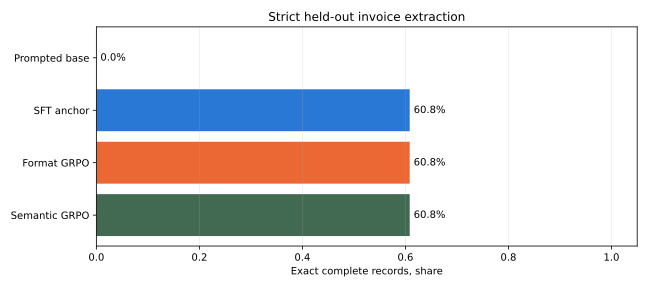

In [13]:
summaries = {key: summary(scores) for key, scores in methods.items()}
slice_scores = {
    method: {label: summary([row for row in scores if row["split"] == label])
             for label in ("familiar", "novel", "independent")}
    for method, scores in methods.items()
}
changes = {"format minus warm": paired_change(warm_result, predictions["format"]),
           "semantic minus warm": paired_change(warm_result, predictions["semantic"]),
           "semantic minus format": paired_change(predictions["format"], predictions["semantic"])}
display(pd.DataFrame(summaries).T)
plot_slices(summaries, "Strict held-out invoice extraction", "04-exact.svg")

## 9. Can you trace every result back to an invoice or update?

    Save the held-out texts, reference records, raw model outputs, reward and budget logs, and profile
    receipt. Use these records to distinguish a changed answer from a changed training metric.

In [14]:
paired_rows = list(zip(teaching, predictions["format"], predictions["semantic"], strict=True))
examples = []
for split in ("familiar", "novel", "independent"):
    candidates = [row for row in paired_rows if row[0].split == split]
    picked = min(candidates, key=lambda row: (row[1]["exact"] == row[2]["exact"], row[1]["exact"]))
    item, format_row, semantic_row = picked
    examples.append({"key": item.key, "split": split, "invoice": invoice_text(item),
                     "expected": packed(invoice_record(item)), "Format GRPO": format_row["completion"],
                     "Semantic GRPO": semantic_row["completion"],
                     "format_exact": format_row["exact"], "semantic_exact": semantic_row["exact"]})
for item in examples:
    print(json.dumps(item, ensure_ascii=False, indent=2))
write_report("04", {
    "catalog_sha256": manifest(catalog), "merged_anchor_sha256": anchor_digest,
    "evaluation_ids": [item.key for item in teaching], "sft_ids": [item.key for item in warm_items],
    "grpo_ids": [item.key for item in rl_items], "token_budgets": budgets, "t4_profile": profile,
    "mutation_invoice": {"invoice": invoice_text(example), "expected": packed(invoice_record(example)),
                         "mutations": replay},
    "splits": slice_scores, "overall": summaries, "paired": changes,
    "training": {"warm": warm_stats, **fits},
    "rollout_diagnostics": diagnostics, "length_penalty_diagnostic": diagnostic_lengths,
}, mutations=replay, examples=[{"method": method, **row} for method, rows in methods.items() for row in rows],
   roster=[{"key": item.key, "family": item.family, "split": item.split, "layout": item.layout,
            "invoice": invoice_text(item), "expected": packed(invoice_record(item))} for item in teaching],
   rollouts=[{"arm": arm, **entry} for arm, fit in fits.items() for entry in fit["audit"]],
   worked_examples=examples)

{
  "key": "SF-732205",
  "split": "familiar",
  "invoice": "Sample Supplier 8519 billing memo / 2026-08-09\nAccount invoice SF-732205 [USD]\n1 x Bench calibration @ 96.66 per unit\nTotal due 103.43 including tax 6.77; net amount 96.66.",
  "expected": "{\"invoice_id\":\"SF-732205\",\"issued_on\":\"2026-08-09\",\"supplier\":\"Sample Supplier 8519\",\"currency\":\"USD\",\"line_items\":[{\"description\":\"Bench calibration\",\"quantity\":1,\"unit_minor\":9666}],\"subtotal_minor\":9666,\"tax_minor\":677,\"total_minor\":10343}",
  "Format GRPO": "{\"invoice_id\":\"SF-732205\",\"issued_on\":\"2026-08-09\",\"supplier\":\"Sample Supplier 8519\",\"currency\":\"USD\",\"line_items\":[{\"description\":\"Bench calibration\",\"quantity\":1,\"unit_minor\":9666}],\"subtotal_minor\":10343,\"tax_minor\":677,\"total_minor\":9666}",
  "Semantic GRPO": "{\"invoice_id\":\"SF-732205\",\"issued_on\":\"2026-08-09\",\"supplier\":\"Sample Supplier 8519\",\"currency\":\"USD\",\"line_items\":[{\"description\":\"B

## Sources

    [DeepSeekMath](https://arxiv.org/html/2402.03300) · [DAPO](https://arxiv.org/html/2503.14476) ·
    [TRL 0.19.1 GRPO implementation](https://github.com/huggingface/trl/blob/v0.19.1/trl/trainer/grpo_trainer.py) ·
    [Apache-licensed cookbook revision](https://github.com/togethercomputer/post-training-cookbook/tree/226e03ca225d6f13434047cf0f45ab3070a29801)

## Read the result

Use the mutation replay to decide what the verifier pays for. Use matched held-out invoices and the independent scorer to decide whether to adopt it.

[Return to the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/04-design-verifiable-rewards).